# Day 36 Prediction Customers Churn Using Random Forest with Feature Importance

Bagi perusahaan, mempertahankan pelanggan lama jauh lebih murah daripada mencari pelanggan baru. Maka memprediksi pelanggan yang akan **berhenti berlangganan (churn)** sangat berharga.

Di notebook ini saya membangun model **Random Forest** untuk memprediksi churn dan yang penting, **mencari tahu faktor apa yang paling memengaruhi** lewat *feature importance*.

> 🎯 **Tujuan Pembelajaran**
> - Membersihkan kolom bermasalah (`TotalCharges` berisi spasi).
> - **Encoding** banyak kolom kategori sekaligus.
> - Melatih **Random Forest** dan membaca **feature_importances_**.
> - Mengevaluasi dengan confusion matrix & classification report.

## Tentang Dataset

Saya memakai **Telco Customer Churn**.

- **Sumber:** [Kaggle — blastchar/telco-customer-churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
- **Target:** kolom `Churn` (Yes = berhenti, No = bertahan).

| Kolom (sebagian) | Arti |
|------------------|------|
| `gender`, `SeniorCitizen`, `Partner`, `Dependents` | Demografi pelanggan |
| `tenure` | Lama berlangganan (bulan) |
| `Contract` | Jenis kontrak (bulanan / 1 thn / 2 thn) |
| `MonthlyCharges` | Tagihan bulanan |
| `TotalCharges` | Total tagihan (perlu dibersihkan!) |
| `InternetService`, `OnlineSecurity`, ... | Layanan yang diambil |
| `Churn` | **Label**: Yes / No |

## Import Library

- **pandas / numpy** → olah data.
- **matplotlib / seaborn** → grafik.
- **scikit-learn** → encoding, split, RandomForest, dan metrik.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

## Import Dataset

In [3]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d blastchar/telco-customer-churn
!unzip telco-customer-churn.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
License(s): copyright-authors
100% 172k/172k [00:00<00:00, 35.3MB/s]

Archive:  telco-customer-churn.zip
  inflating: WA_Fn-UseC_-Telco-Customer-Churn.csv  


## Eksplorasi Awal Dataset

In [4]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("Nama kolom:", list(df.columns))
print(f'Banyak baris: {df.shape[0]}')
print(f'Banyak kolom: {df.shape[1]}')
print(f'Banyak nilai null: {df.isna().sum().sum()}')
print(df.isnull().sum())
df.info()

Nama kolom: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
Banyak baris: 7043
Banyak kolom: 21
Banyak nilai null: 0
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            No

**Interpretasi:**
- Banyak kolom kategori berupa teks (Yes/No, jenis layanan). `customerID` hanya identitas (akan dibuang).
- `TotalCharges` terlihat numerik, tetapi masih berupa object.Ini pertanda ada nilai non-numerik tersembunyi di dalamnya.

In [6]:
# Cek nilai TotalCharges yang berupa spasi/kosong
spc = df[df['TotalCharges'] == ' ']

print(f'Banyak baris yang berisi spasi: {spc.shape[0]}')
spc.head()

Banyak baris yang berisi spasi: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No


**Interpretasi:**
- Terdapat 11 Baris dalam `TotalCharges` berisi spasi/kosong

## Cleaning Data

Langkah pembersihan:

1. Ubah spasi pada `TotalCharges` menjadi `NaN`, lalu konversi kolom ke numerik.
2. Karena baris bermasalah punya `tenure=0`, kita isi `TotalCharges`-nya dengan 0 (lebih masuk akal daripada drop, sebab pelanggan baru memang belum menumpuk tagihan).
3. Buang kolom `customerID` yang tidak informatif.

In [8]:
#ubah spasi jadi nan
df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')


In [9]:
#New_Customers tenure 0 = total tagihan 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [10]:
#drop kolom ID
df.drop('customerID', axis=1, inplace=True)
print(list(df.columns))
print(f'Banyak baris: {df.shape[0]}')
print(f'Banyak kolom: {df.shape[1]}')

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
Banyak baris: 7043
Banyak kolom: 20


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


**Interpretasi:**
- `TotalCharges` kini bertipe numerik tanpa nilai hilang. Kolom identitas sudah dibuang. Data siap untuk encoding.

## Exploratory Data Analysis and Visualization

### a) Sebaran Churn

/tmp/ipykernel_4855/4158215920.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='Churn', data=df, palette="Set2")


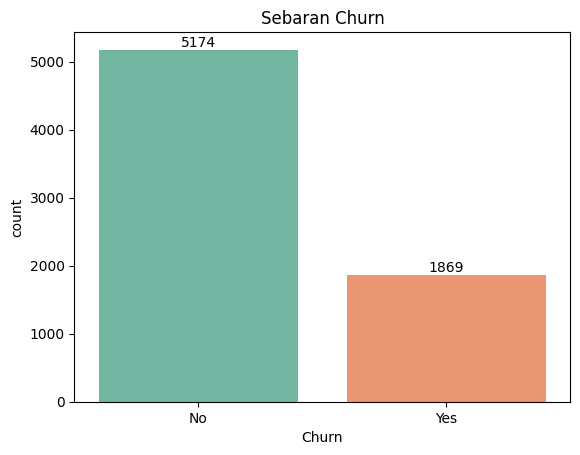

Churn
No     0.73
Yes    0.27
Name: proportion, dtype: float64


In [20]:
ax = sns.countplot(x='Churn', data=df, palette="Set2")
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title('Sebaran Churn')
plt.show()

print(df['Churn'].value_counts(normalize=True).round(2))

**Interpretasi:**
- Sekitar 26% Pelanggan Churn berdasarkan data dengan jumlah 1869 Customer
- Untuk pelanggan yang tidak Churn sebanyak 73% atau sekitar 5174 Customer
- Data ini Tidak Seimbang

### b) Sebaran Churn Berdasarkan Jenis Kontrak

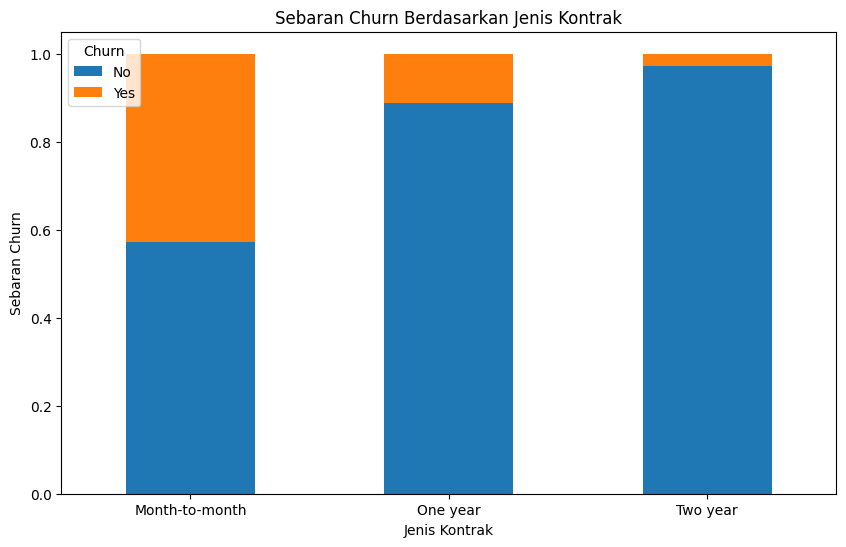

In [22]:
ct = pd.crosstab(df['Contract'], df['Churn'], normalize="index")
ct.plot(kind='bar', stacked=True, figsize=(10, 6))


plt.title('Sebaran Churn Berdasarkan Jenis Kontrak')
plt.xlabel('Jenis Kontrak')
plt.ylabel('Sebaran Churn')
plt.legend(title='Churn')
plt.xticks(rotation=0)
plt.show()

**Interpretasi:**

- Kontrak Bulanan (Month-to-month): Paling rawan berhenti (churn paling tinggi) karena pelanggan tidak terikat komitmen jangka panjang.   
- Kontrak 1 Tahun & 2 Tahun: Jauh lebih setia (loyal), di mana tingkat churn-nya sangat kecil karena pelanggan cenderung bertahan hingga kontrak selesai.   

Kesimpulan bisnis:
- Perusahaan perlu memberikan insentif atau promosi agar pelanggan kontrak bulanan mau beralih ke kontrak jangka panjang.

### c) Panjang Tenure berdasarkan Status Churn

/tmp/ipykernel_4855/1442241265.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn', y='tenure', data=df, palette="Set2")


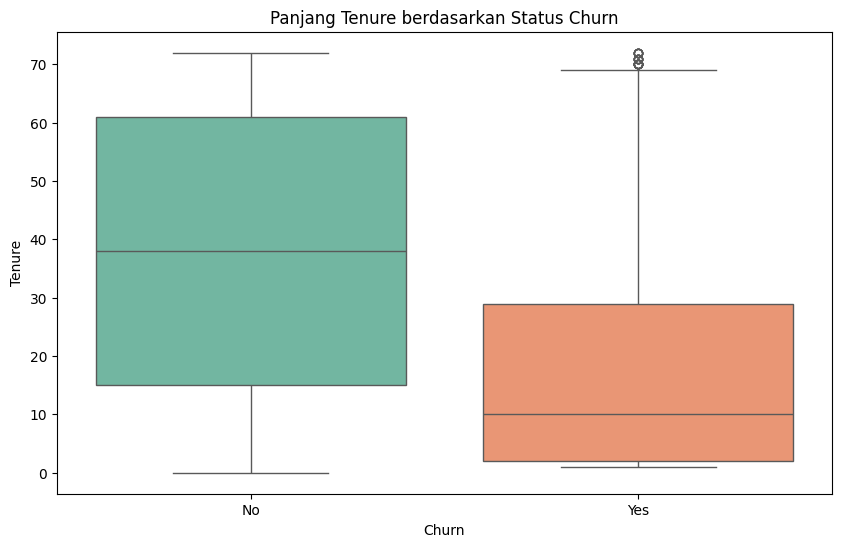

In [23]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Churn', y='tenure', data=df, palette="Set2")
plt.title('Panjang Tenure berdasarkan Status Churn')
plt.xlabel('Churn')
plt.ylabel('Tenure')
plt.show()

**Interpretasi:**

- Status No (Tetap Berlangganan): Garis tengah (median) tenure-nya berada di sekitar angka 38 bulan, dengan sebagian besar data berada di rentang masa langganan yang panjang.   
- Status Yes (Churn): Sebagian besar pelanggan yang berhenti memiliki tenure yang pendek, dengan median hanya sekitar 10 bulan.   

Kesimpulan bisnis:
- Semakin lama pelanggan berlangganan, semakin kecil kemungkinan mereka untuk melakukan churn. Tantangan utamanya adalah mempertahankan pelanggan di masa-masa awal langganan (terutama di bawah 1 tahun) agar mereka bisa menjadi lebih loyal.  

## Preprocessing Data ( Encoding & Splitting )

Banyak kolom kategori. Kita ubah semua kolom bertipe `object` menjadi angka dengan **LabelEncoder** (otomatis untuk tiap kolom kategori), lalu pisahkan fitur & target.

In [24]:
data = df.copy()

In [25]:
#Encode kolom Target
data['Churn'] = data['Churn'].map({'No': 0, 'Yes': 1})

#Encodde semua kolom kategori (Object) lainnya
cat_kol = data.select_dtypes(include='object').columns.to_list()

for col in cat_kol:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])

In [26]:
#Pisahkan X dan Y
X = data.drop('Churn', axis=1)
y = data['Churn']

In [27]:
#Pisahkan Data latih dan Data Test
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

In [28]:
#Check proporsi masing masing data baru
print(f'Jumlah data latih: {len(X_train)}')
print(f'Jumlah data test: {len(X_test)}')
print(f'Proporsi data latih: {y_train.value_counts(normalize=True).round(2)}')
print(f'Proporsi data test: {y_test.value_counts(normalize=True).round(2)}')

Jumlah data latih: 5634
Jumlah data test: 1409
Proporsi data latih: Churn
0    0.73
1    0.27
Name: proportion, dtype: float64
Proporsi data test: Churn
0    0.73
1    0.27
Name: proportion, dtype: float64


**Interpretasi:**

- Pembagian Data (Split): Dataset telah dibagi menjadi data latih (train) sebanyak 5.634 baris dan data uji (test) sebanyak 1.409 baris.

- Proporsi Seimbang: Proporsi kelas churn pada data latih dan data uji sangat konsisten (73% pelanggan bertahan / 0 dan 27% pelanggan churn / 1).

Kesimpulan:
  - Pembagian data sudah ideal dan representatif, sehingga model Machine Learning nantinya akan belajar dan diuji pada karakteristik data yang seimbang.

## Modeling

Random Forest = gabungan banyak pohon keputusan yang dilatih pada subset data/fitur acak, lalu memungut suara mayoritas. Hasilnya lebih stabil & akurat dibanding pohon tunggal.

In [29]:
from IPython.utils.syspathcontext import prepended_to_syspath
rf = RandomForestClassifier(n_estimators=300,
                            n_jobs=1,
                            random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

## Evaluation

In [32]:
print(f'Akurasi: {accuracy_score(y_test, pred_rf):.2f}')
print(f'Confusion Matrix:\n{confusion_matrix(y_test, pred_rf)}')
print(f'Classification Report:\n{classification_report(y_test, pred_rf)}')

Akurasi: 0.79
Confusion Matrix:
[[929 106]
 [185 189]]
Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.64      0.51      0.57       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.71      1409
weighted avg       0.78      0.79      0.79      1409



**Interpretasi:**

  - Akurasi Keseluruhan (79%): Secara total, model mampu melakukan prediksi dengan benar pada 79% dari keseluruhan data uji (1.118 dari 1.409 data).

  - Performa Kelas 0 (Tidak Churn): Sangat baik. Model sangat handal mengenali pelanggan yang bertahan (memiliki recall tinggi 0.90), sehingga sedikit sekali pelanggan setia yang salah diprediksi sebagai churn.

  - Performa Kelas 1 (Churn): Kurang optimal. Dari 374 pelanggan yang benar-benar churn, model hanya berhasil mendeteksi sekitar separuhnya (recall 0.51), dan dari semua prediksi churn yang dibuat model, hanya 64% yang benar (precision 0.64).

Kesimpulan:
  - Model sangat jago mendeteksi pelanggan yang bertahan, tetapi masih sering kecolongan dalam mendeteksi pelanggan yang benar-benar akan churn.

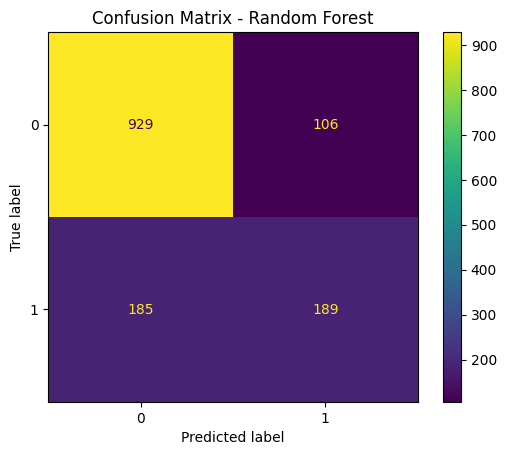

In [34]:
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_rf)).plot()
plt.title('Confusion Matrix - Random Forest')
plt.show( )

Interpretasi:

 - Akurasi Keseluruhan (79%): Secara total, model mampu melakukan prediksi dengan benar pada 79% dari keseluruhan data uji (1.118 dari 1.409 data).

  - Performa Kelas 0 (Tidak Churn): Sangat baik. Model sangat handal mengenali pelanggan yang bertahan (memiliki recall tinggi 0.90), sehingga sedikit sekali pelanggan setia yang salah diprediksi sebagai churn.

  - Performa Kelas 1 (Churn): Kurang optimal. Dari 374 pelanggan yang benar-benar churn, model hanya berhasil mendeteksi sekitar separuhnya (recall 0.51), dan dari semua prediksi churn yang dibuat model, hanya 64% yang benar (precision 0.64).

Kesimpulan:
  - Model sangat jago mendeteksi pelanggan yang bertahan, tetapi masih sering kecolongan dalam mendeteksi pelanggan yang benar-benar akan churn.

### Feature Importance

/tmp/ipykernel_4855/1579288184.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.text(imp[i], i, round(imp[i], 2), ha='left')


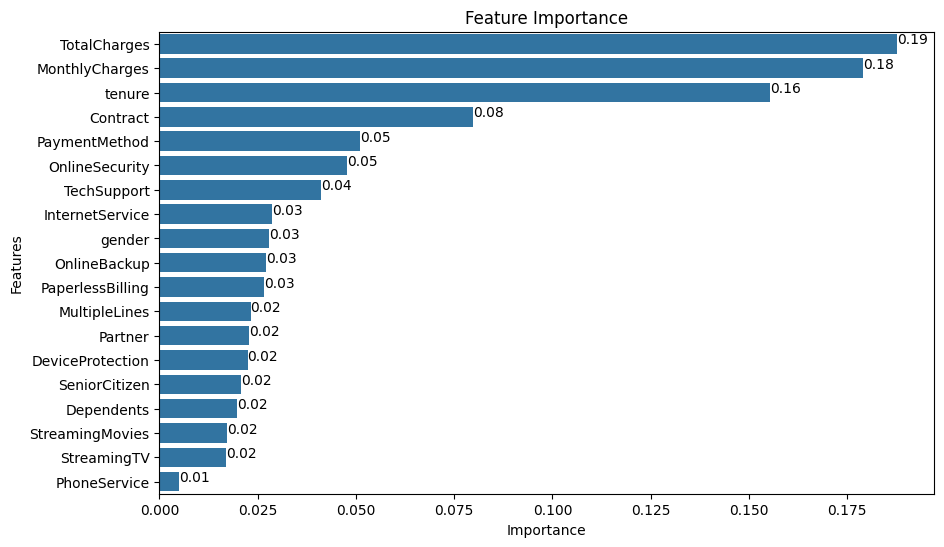

In [37]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=imp, y=imp.index)
plt.title('Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')
for i in range(len(imp)):
    plt.text(imp[i], i, round(imp[i], 2), ha='left')
plt.show()

**Interpretasi:**

- Faktor Paling Menentukan (Top 3):
  - TotalCharges (0.19), MonthlyCharges (0.18), dan tenure (0.16) adalah tiga variabel yang paling kuat memengaruhi keputusan model dalam menentukan apakah pelanggan akan churn atau tidak.
  - Biaya total, biaya bulanan, dan lama berlangganan memegang peran terbesar.   

- Faktor Pendukung Penting:
  - Contract (0.08) menyusul di urutan berikutnya, yang sejalan dengan analisis kita sebelumnya bahwa jenis kontrak sangat memengaruhi potensi churn.   


- Faktor Lainnya:
  - Variabel seperti metode pembayaran (PaymentMethod), keamanan online (OnlineSecurity), hingga dukungan teknis (TechSupport) memiliki pengaruh yang makin mengecil. Sementara fitur seperti jenis kelamin (gender) atau layanan telepon (PhoneService) hampir tidak berpengaruh bagi model.   
  
Kesimpulan:
  - Faktor finansial (biaya bulanan dan total) serta masa langganan (tenure) adalah penentu utama mengapa pelanggan bertahan atau berhenti.   

### **Kesimpulan Utama & Rekomendasi Bisnis**

Berdasarkan eksplorasi data (EDA) dan hasil pemodelan menggunakan **Random Forest Classifier**, berikut adalah kesimpulan utama serta rekomendasi strategis untuk menekan angka *churn* pelanggan:

#### **1. Faktor Finansial dan Retensi Adalah Kunci Utama**
* **Temuan:** Fitur `TotalCharges` (0.19), `MonthlyCharges` (0.18), dan `tenure` (0.16) merupakan tiga faktor terbesar yang memengaruhi keputusan pelanggan untuk berhenti berlangganan.
* **Rekomendasi:**
  * **Intervensi Awal:** Diketahui median masa berlangganan (*tenure*) pelanggan yang *churn* sangat singkat (hanya sekitar 10 bulan). Perusahaan harus memberikan perhatian khusus berupa program *nurturing* atau penawaran loyalitas sebelum pelanggan mencapai masa 1 tahun pertama.
  * **Optimasi Harga:** Lakukan evaluasi berkala pada paket harga bulanan (`MonthlyCharges`). Berikan insentif berupa diskon progresif bagi pelanggan yang bersedia memperpanjang masa langganan.

#### **2. Migrasi Jenis Kontrak**
* **Temuan:** Analisis korelasi menunjukkan pelanggan dengan kontrak **Month-to-month** memiliki tingkat *churn* yang sangat tinggi (mencapai ~42%), jauh melampaui pelanggan kontrak 1 tahun atau 2 tahun.
* **Rekomendasi:**
  * Buat kampanye pemasaran yang menarik untuk memigrasikan pelanggan bulanan ke kontrak tahunan (misalnya: *"Bayar 10 Bulan untuk Kontrak 1 Tahun"*).
  * Batasi kemudahan berhenti tanpa penalti pada kontrak bulanan dengan menawarkan opsi pembekuan layanan sementara (*freeze account*) alih-alih langsung berhenti berlangganan.

#### **3. Evaluasi Performa Model Prediksi**
* **Temuan:** Model Random Forest saat ini mencapai akurasi **79%**. Namun, performa mendeteksi pelanggan yang benar-benar akan *churn* (Recall Kelas 1) masih sebesar **51%**.
* **Rekomendasi Pengembangan Model:**
  * Untuk iterasi berikutnya, gunakan teknik penanganan ketidakseimbangan kelas (*class imbalance*) seperti **SMOTE** (Synthetic Minority Over-sampling Technique) atau atur parameter `class_weight='balanced'` pada Random Forest.
  * Lakukan *hyperparameter tuning* (menggunakan GridSearchCV/RandomizedSearchCV) untuk mengoptimalkan kinerja *recall* target *churn* (Kelas 1) agar tidak banyak pelanggan *churn* yang luput dari prediksi.
